# Speaker Identification with GMMs (trained from scratch)

**Pipeline:** silence removal → 20 MFCC + Δ + ΔΔ (60-dim, CMVN) → one diagonal-covariance GMM per speaker → predict the speaker whose GMM gives the highest average log-likelihood.

**Data:** works with both a folder of per-sentence WAVs and a single long WAV. All speakers are treated the same way, by amount of speech:
- **Test set:** the last 3 minutes of speech per speaker (never used for training), cut into clips of 0.5 / 1 / 2 / 3 s.
- **Training conditions** are defined in *sentences* and converted to seconds of speech using the measured average speech per sentence (from the speakers recorded as one file per sentence). The largest condition is capped at what every speaker has after the test set is held out.

**Metrics:**
- **Identification accuracy** (closed-set, 4 speakers) and **confusion matrices**.
- **Equal Error Rate (EER)**: each test clip is scored against every speaker model as a verification trial (score = log-likelihood of the claimed speaker − mean log-likelihood of the other speakers); EER is where false-accept rate = false-reject rate. Lower is better, and it still separates systems when accuracy reaches 100 %.

Run with *Runtime → Run all*.

### Saved model
The first full run trains everything and saves the best model (64-component GMMs, all training data) to `results/gmm_best_model.joblib` on Drive.
On later runs, the notebook loads that file and **skips Sections 5–9**, going straight to the live demo (Section 10).
To retrain from scratch, delete `gmm_best_model.joblib` from Drive.

## 1. Connect Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/speech_assignment_data/data'
OUT      = '/content/drive/MyDrive/speech_assignment_data/results'

import os
print('Contents of DATA_DIR:')
for name in sorted(os.listdir(DATA_DIR)):
    p = os.path.join(DATA_DIR, name)
    print('  ', name, f'({len(os.listdir(p))} files)' if os.path.isdir(p) else f'({os.path.getsize(p)/1e6:.0f} MB)')

Mounted at /content/drive
Contents of DATA_DIR:
   hari_prakash_audio.wav (240 MB)
   speech_rec.wav (568 MB)
   spk01 (550 files)
   spk02 (501 files)


## 2. Settings

In [2]:
SPEAKERS = {
    'spk01': 'spk01',
    'spk02': 'spk02',
    'spk03': 'hari_prakash_audio.wav',
    'spk04': 'speech_rec.wav',
    # 'spk05': 'spk05',
}

SR = 16000                          # everything is resampled to 16 kHz
TEST_SECONDS = 180                  # last 3 min of speech per speaker = test set
TRAIN_SENTENCES = [10, 30, 100, 500]  # training conditions (500 is capped to what everyone has)
N_COMPONENTS = [8, 16, 32, 64]
TEST_LENGTHS = [0.5, 1.0, 2.0, 3.0]   # test clip lengths (s)
FOCUS_LENGTH = 1.0                  # clip length used for the main plots / confusion matrices
SEED = 0

# Display names (the model itself uses the speaker codes above)
NAMES = {'spk01': 'Justin', 'spk02': 'Venkatesh', 'spk03': 'Hari Prakash', 'spk04': 'Job'}
who = lambda spk: f"{NAMES.get(spk, spk)} ({spk})"


## 3. Audio loading and silence removal

In [3]:
import glob, time
import numpy as np
import soundfile as sf
from scipy.signal import resample_poly

def load_wav(path):
    y, sr = sf.read(path, always_2d=True, dtype='float32')
    y = y.mean(axis=1)
    if sr != SR:
        g = np.gcd(sr, SR)
        y = resample_poly(y, SR // g, sr // g).astype('float32')
    return y

def load_speaker(src):
    """One long 1-D array of the speaker's audio in recording order, plus number of files."""
    if os.path.isdir(src):
        files = sorted(glob.glob(os.path.join(src, '**', '*.wav'), recursive=True))
        if not files:
            raise FileNotFoundError(f'No WAV files in folder {src}')
        return np.concatenate([load_wav(f) for f in files]), len(files)
    return load_wav(src), 1

def remove_silence(y, frame_ms=20, threshold=0.1):
    """Keep only frames louder than threshold x typical speech level."""
    frame = int(SR * frame_ms / 1000)
    n = len(y) // frame
    frames = y[: n * frame].reshape(n, frame)
    rms = np.sqrt((frames ** 2).mean(axis=1) + 1e-12)
    return frames[rms > threshold * np.percentile(rms, 95)].reshape(-1)

def chunks(y, seconds):
    L = int(seconds * SR)
    return [y[i:i + L] for i in range(0, len(y) - L + 1, L)]

## 4. Features: MFCC + Δ + ΔΔ with CMVN

In [4]:
from scipy.fft import dct

def _mel_filterbank(n_fft=512, n_mels=40, fmin=20, fmax=SR / 2):
    hz2mel = lambda f: 2595 * np.log10(1 + f / 700)
    mel2hz = lambda m: 700 * (10 ** (m / 2595) - 1)
    mels = np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2)
    bins = np.floor((n_fft + 1) * mel2hz(mels) / SR).astype(int)
    fb = np.zeros((n_mels, n_fft // 2 + 1))
    for m in range(1, n_mels + 1):
        l, c, r = bins[m - 1], bins[m], bins[m + 1]
        if c > l: fb[m - 1, l:c] = (np.arange(l, c) - l) / (c - l)
        if r > c: fb[m - 1, c:r] = (r - np.arange(c, r)) / (r - c)
    return fb

MEL_FB = _mel_filterbank()

def _delta(x, N=2):
    pad = np.pad(x, ((N, N), (0, 0)), mode='edge')
    num = sum(n * (pad[N + n: len(x) + N + n] - pad[N - n: len(x) + N - n]) for n in range(1, N + 1))
    return num / (2 * sum(n * n for n in range(1, N + 1)))

def mfcc_features(y, n_mfcc=20, win=0.025, hop=0.010, n_fft=512):
    """20 MFCC + delta + delta-delta, CMVN per segment. Returns (frames, 60)."""
    y = np.append(y[0], y[1:] - 0.97 * y[:-1])            # pre-emphasis
    wl, hl = int(win * SR), int(hop * SR)
    if len(y) < wl:
        return np.zeros((0, 3 * n_mfcc))
    n = 1 + (len(y) - wl) // hl
    idx = np.arange(wl)[None, :] + hl * np.arange(n)[:, None]
    frames = y[idx] * np.hamming(wl)
    power = np.abs(np.fft.rfft(frames, n_fft)) ** 2 / n_fft
    logmel = np.log(power @ MEL_FB.T + 1e-10)
    c = dct(logmel, type=2, axis=1, norm='ortho')[:, :n_mfcc]
    f = np.hstack([c, _delta(c), _delta(_delta(c))])
    return (f - f.mean(0)) / (f.std(0) + 1e-8)

## 4b. Load the saved best model (if it exists)

In [5]:
import joblib
MODEL_PATH = os.path.join(OUT, 'gmm_best_model.joblib')
os.makedirs(OUT, exist_ok=True)

HAVE_MODEL = os.path.exists(MODEL_PATH)
if HAVE_MODEL:
    bundle = joblib.load(MODEL_PATH)
    models, labels, demo_clips = bundle['models'], bundle['labels'], bundle['demo_clips']
    print(f"Loaded saved model: {bundle['components']}-component GMMs for {labels} "
          f"({bundle['train_seconds']} s of training speech per speaker).")
    print('Sections 5-9 will be skipped. Jump to Section 10 for the demo.')
else:
    print('No saved model found - Sections 5-9 will train and evaluate everything (~15 min).')

No saved model found - Sections 5-9 will train and evaluate everything (~15 min).


## 5. Load speakers, train/test split, training conditions

In [6]:
if HAVE_MODEL:
    print('Skipped loading audio (saved model loaded). Delete {} to retrain.'.format(MODEL_PATH))
else:
    labels = list(SPEAKERS)
    speech, nfiles = {}, {}
    for spk, rel in SPEAKERS.items():
        t = time.time()
        raw, nfiles[spk] = load_speaker(os.path.join(DATA_DIR, rel))
        speech[spk] = remove_silence(raw)
        print(f'{spk}: {nfiles[spk]} file(s), {len(raw)/SR/60:.1f} min total, '
              f'{len(speech[spk])/SR/60:.1f} min of speech  ({time.time()-t:.0f}s)')

    # average seconds of speech per sentence, measured on the one-file-per-sentence speakers
    per_sent = [len(speech[s]) / SR / nfiles[s] for s in labels if nfiles[s] > 1]
    SEC_PER_SENT = float(np.mean(per_sent)) if per_sent else 2.0
    print(f'\nAverage speech per sentence: {SEC_PER_SENT:.2f} s')

    test_audio, train_pool = {}, {}
    for spk, sp in speech.items():
        cut = len(sp) - int(TEST_SECONDS * SR)
        if cut <= 0:
            raise ValueError(f'{spk} has less than {TEST_SECONDS}s of speech')
        train_pool[spk], test_audio[spk] = sp[:cut], sp[cut:]
    available = min(len(v) for v in train_pool.values()) / SR

    conditions = {}   # label -> training seconds
    for n in TRAIN_SENTENCES:
        secs = n * SEC_PER_SENT
        if secs > available:
            secs = available
            label = f'{n} sent. (capped: {secs:.0f} s ≈ {secs / SEC_PER_SENT:.0f} sent.)'
        else:
            label = f'{n} sent. ({secs:.0f} s)'
        conditions[label] = secs
    print('Training conditions (seconds of speech per speaker):')
    for k, v in conditions.items():
        print(f'   {k}')

    test_feats = {}
    for L in TEST_LENGTHS:
        X, y = [], []
        for spk in labels:
            for clip in chunks(test_audio[spk], L):
                X.append(mfcc_features(clip)); y.append(spk)
        test_feats[L] = (X, np.array(y))
        print(f'Test clips of {L:g} s: {len(y)} ({len(y) // len(labels)} per speaker)')

spk01: 550 file(s), 35.7 min total, 18.1 min of speech  (16s)
spk02: 501 file(s), 53.7 min total, 18.4 min of speech  (12s)
spk03: 1 file(s), 41.7 min total, 25.6 min of speech  (9s)
spk04: 1 file(s), 49.3 min total, 25.5 min of speech  (14s)

Average speech per sentence: 2.09 s
Training conditions (seconds of speech per speaker):
   10 sent. (21 s)
   30 sent. (63 s)
   100 sent. (209 s)
   500 sent. (capped: 904 s ≈ 434 sent.)
Test clips of 0.5 s: 1440 (360 per speaker)
Test clips of 1 s: 720 (180 per speaker)
Test clips of 2 s: 360 (90 per speaker)
Test clips of 3 s: 240 (60 per speaker)


## 6. Train GMMs and evaluate (accuracy + EER)

In [7]:
if HAVE_MODEL:
    print('Skipped training (saved model loaded). Delete {} to retrain.'.format(MODEL_PATH))
else:
    from sklearn.mixture import GaussianMixture
    from sklearn.metrics import confusion_matrix, roc_curve
    import warnings
    warnings.filterwarnings('ignore')

    def eer(scores, y_true):
        """Equal error rate (%) from an (n_clips, n_speakers) score matrix."""
        tgt, non = [], []
        for i, spk in enumerate(labels):
            others = np.delete(scores, i, axis=1).mean(axis=1)
            s = scores[:, i] - others                      # claimed speaker vs the rest
            tgt.append(s[y_true == spk]); non.append(s[y_true != spk])
        tgt, non = np.concatenate(tgt), np.concatenate(non)
        fpr, tpr, _ = roc_curve(np.r_[np.ones(len(tgt)), np.zeros(len(non))], np.r_[tgt, non])
        fnr = 1 - tpr
        i = np.nanargmin(np.abs(fnr - fpr))
        return 100 * (fpr[i] + fnr[i]) / 2

    rows, cms = [], {}
    for cond, secs in conditions.items():
        train_feats = {spk: np.vstack([mfcc_features(c) for c in chunks(train_pool[spk][: int(secs * SR)], 3.0)])
                       for spk in labels}
        for k in N_COMPONENTS:
            t = time.time()
            models = {spk: GaussianMixture(k, covariance_type='diag', max_iter=200, reg_covar=1e-3,
                                           random_state=SEED).fit(train_feats[spk]) for spk in labels}
            row = {'condition': cond, 'train_seconds': round(secs), 'components': k}
            for L, (X, y_true) in test_feats.items():
                S = np.array([[models[s].score(f) for s in labels] for f in X])   # avg log-likelihoods
                y_pred = np.array(labels)[S.argmax(1)]
                row[f'acc_{L:g}s'] = round(100 * np.mean(y_pred == y_true), 2)
                row[f'eer_{L:g}s'] = round(eer(S, y_true), 2)
                cms[(cond, k, L)] = confusion_matrix(y_true, y_pred, labels=labels)
            rows.append(row)
            print(f'{cond:34s} {k:3d} comp | ' +
                  ' | '.join(f"{L:g}s acc {row[f'acc_{L:g}s']:6.2f}% EER {row[f'eer_{L:g}s']:5.2f}%" for L in TEST_LENGTHS) +
                  f'  ({time.time()-t:.0f}s)')

10 sent. (21 s)                      8 comp | 0.5s acc  88.12% EER  8.96% | 1s acc  94.58% EER  4.84% | 2s acc  99.44% EER  1.90% | 3s acc  98.33% EER  1.18%  (6s)
10 sent. (21 s)                     16 comp | 0.5s acc  90.07% EER  7.60% | 1s acc  95.83% EER  4.14% | 2s acc  98.89% EER  1.30% | 3s acc  99.58% EER  1.18%  (7s)
10 sent. (21 s)                     32 comp | 0.5s acc  91.39% EER  7.43% | 1s acc  95.83% EER  3.77% | 2s acc  98.61% EER  1.99% | 3s acc  98.33% EER  1.04%  (13s)
10 sent. (21 s)                     64 comp | 0.5s acc  90.90% EER  7.78% | 1s acc  94.72% EER  4.47% | 2s acc  97.22% EER  2.22% | 3s acc  97.92% EER  2.01%  (15s)
30 sent. (63 s)                      8 comp | 0.5s acc  92.50% EER  6.26% | 1s acc  98.33% EER  2.08% | 2s acc 100.00% EER  0.32% | 3s acc 100.00% EER  0.00%  (8s)
30 sent. (63 s)                     16 comp | 0.5s acc  94.79% EER  4.22% | 1s acc  99.31% EER  1.09% | 2s acc 100.00% EER  0.00% | 3s acc 100.00% EER  0.00%  (8s)
30 sent. (63 s

## 7. Results tables

In [8]:
if HAVE_MODEL:
    print('Skipped results tables (saved model loaded). Delete {} to retrain.'.format(MODEL_PATH))
else:
    import pandas as pd
    import matplotlib.pyplot as plt
    os.makedirs(OUT, exist_ok=True)

    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(OUT, 'gmm_results.csv'), index=False)
    cond_order = list(conditions)

    for metric in ['acc', 'eer']:
        name = 'Accuracy (%)' if metric == 'acc' else 'EER (%)'
        t = df.pivot(index='condition', columns='components', values=f'{metric}_{FOCUS_LENGTH:g}s').loc[cond_order]
        print(f'{name} on {FOCUS_LENGTH:g} s test clips:'); display(t)
        t.to_csv(os.path.join(OUT, f'{metric}_{FOCUS_LENGTH:g}s_table.csv'))

    best = df.loc[df.groupby('condition', sort=False)[f'acc_{FOCUS_LENGTH:g}s'].idxmax()]
    print('\nBest model per training condition (chosen by accuracy on', FOCUS_LENGTH, 's clips), all clip lengths:')
    display(best.set_index('condition').loc[cond_order])

Accuracy (%) on 1 s test clips:


components,8,16,32,64
condition,,,,
10 sent. (21 s),94.58,95.83,95.83,94.72
30 sent. (63 s),98.33,99.31,99.58,99.72
100 sent. (209 s),98.89,99.58,99.86,99.86
500 sent. (capped: 904 s ≈ 434 sent.),99.31,99.72,99.86,100.00


EER (%) on 1 s test clips:


components,8,16,32,64
condition,,,,
10 sent. (21 s),4.84,4.14,3.77,4.47
30 sent. (63 s),2.08,1.09,0.90,0.56
100 sent. (209 s),1.81,0.72,0.44,0.28
500 sent. (capped: 904 s ≈ 434 sent.),1.11,0.30,0.12,0.14



Best model per training condition (chosen by accuracy on 1.0 s clips), all clip lengths:


,train_seconds,components,acc_0.5s,eer_0.5s,acc_1s,eer_1s,acc_2s,eer_2s,acc_3s,eer_3s
condition,,,,,,,,,,
10 sent. (21 s),21,16,90.07,7.60,95.83,4.14,98.89,1.3,99.58,1.18
30 sent. (63 s),63,64,97.01,2.84,99.72,0.56,100.00,0.0,100.00,0.00
100 sent. (209 s),209,32,97.22,2.69,99.86,0.44,100.00,0.0,100.00,0.00
500 sent. (capped: 904 s ≈ 434 sent.),904,64,99.31,1.25,100.00,0.14,100.00,0.0,100.00,0.00


## 8. Plots

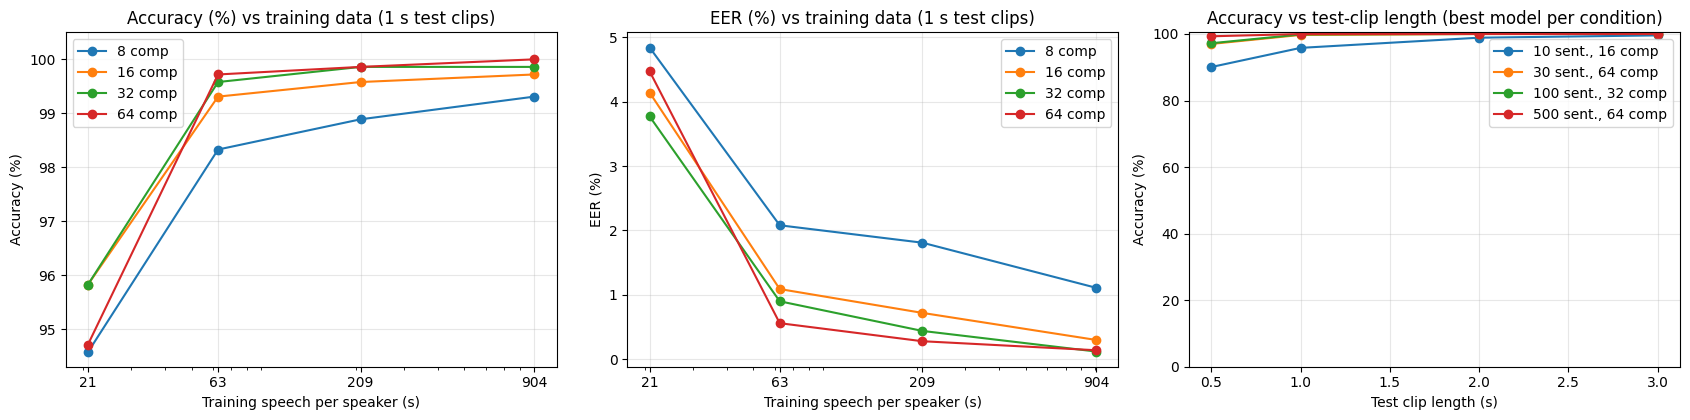

In [9]:
if HAVE_MODEL:
    print('Skipped plots (saved model loaded). Delete {} to retrain.'.format(MODEL_PATH))
else:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
    x = [conditions[c] for c in cond_order]
    for k in N_COMPONENTS:
        g = df[df.components == k].set_index('condition').loc[cond_order]
        axes[0].plot(x, g[f'acc_{FOCUS_LENGTH:g}s'], marker='o', label=f'{k} comp')
        axes[1].plot(x, g[f'eer_{FOCUS_LENGTH:g}s'], marker='o', label=f'{k} comp')
    for ax, t in zip(axes[:2], ['Accuracy (%)', 'EER (%)']):
        ax.set_xscale('log'); ax.set_xticks(x, [f'{v:.0f}' for v in x])
        ax.set_xlabel('Training speech per speaker (s)'); ax.set_ylabel(t)
        ax.set_title(f'{t} vs training data ({FOCUS_LENGTH:g} s test clips)'); ax.grid(alpha=0.3); ax.legend()
    axes[0].set_ylim(top=100.5); axes[2].set_ylim(top=100.5)

    for _, r in best.iterrows():
        axes[2].plot(TEST_LENGTHS, [r[f'acc_{L:g}s'] for L in TEST_LENGTHS], marker='o',
                     label=f"{r['condition'].split(' (')[0]}, {r['components']} comp")
    axes[2].set_xlabel('Test clip length (s)'); axes[2].set_ylabel('Accuracy (%)')
    axes[2].set_title('Accuracy vs test-clip length (best model per condition)'); axes[2].grid(alpha=0.3); axes[2].legend()
    fig.tight_layout(); fig.savefig(os.path.join(OUT, 'gmm_curves.png'), dpi=150); plt.show()

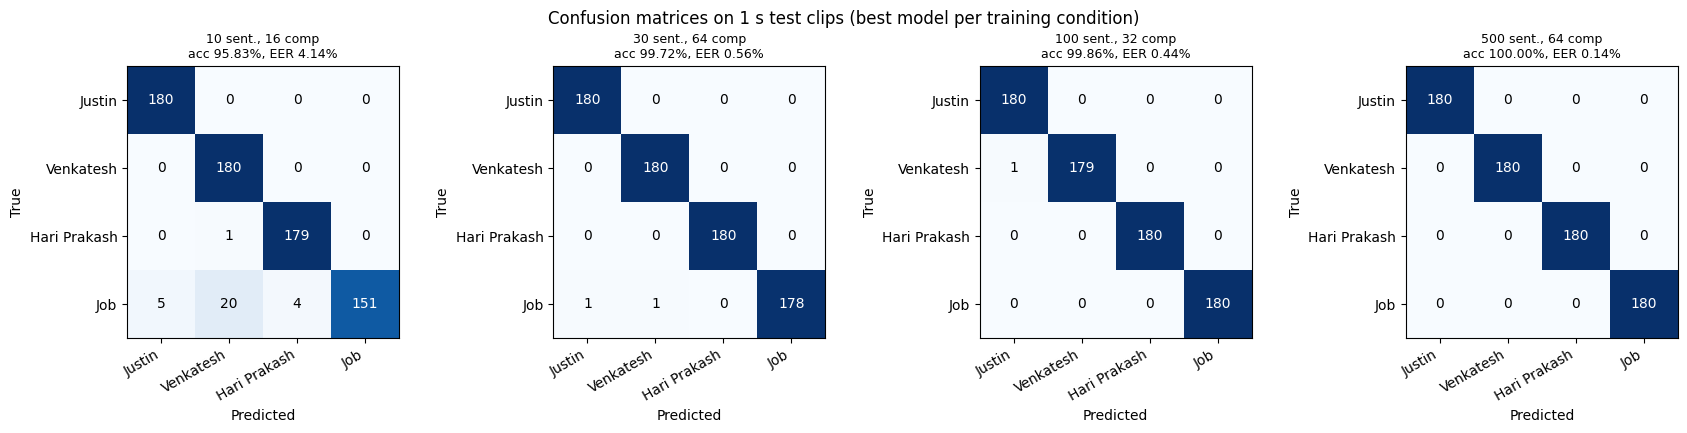

All results saved to /content/drive/MyDrive/speech_assignment_data/results


In [10]:
if HAVE_MODEL:
    print('Skipped confusion matrices (saved model loaded). Delete {} to retrain.'.format(MODEL_PATH))
else:
    fig, axes = plt.subplots(1, len(cond_order), figsize=(4.3 * len(cond_order), 4.2))
    for ax, (_, r) in zip(np.atleast_1d(axes), best.set_index('condition').loc[cond_order].reset_index().iterrows()):
        cm = cms[(r['condition'], r['components'], FOCUS_LENGTH)]
        ax.imshow(cm, cmap='Blues')
        ax.set_xticks(range(len(labels)), [NAMES.get(s, s) for s in labels], rotation=30, ha='right'); ax.set_yticks(range(len(labels)), [NAMES.get(s, s) for s in labels])
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.set_title(f"{r['condition'].split(' (')[0]}, {r['components']} comp\n"
                     f"acc {r[f'acc_{FOCUS_LENGTH:g}s']:.2f}%, EER {r[f'eer_{FOCUS_LENGTH:g}s']:.2f}%", fontsize=9)
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    fig.suptitle(f'Confusion matrices on {FOCUS_LENGTH:g} s test clips (best model per training condition)')
    fig.tight_layout(); fig.savefig(os.path.join(OUT, 'gmm_confusion_matrices.png'), dpi=150); plt.show()
    print('All results saved to', OUT)

## 9. Save the best model to Drive

In [11]:
if HAVE_MODEL:
    print('Skipped saving (saved model loaded). Delete {} to retrain.'.format(MODEL_PATH))
else:
    # 'models' is the last model trained in Section 6: 64 components on the largest training condition
    assert models[labels[0]].n_components == max(N_COMPONENTS)
    rng = np.random.default_rng(0)
    demo_clips = {spk: [test_audio[spk][s: s + 3 * SR]           # held-out 3 s clips for the backup demo
                        for s in rng.choice(len(test_audio[spk]) - 3 * SR, 5, replace=False)]
                  for spk in labels}
    joblib.dump({'models': models, 'labels': labels, 'demo_clips': demo_clips,
                 'components': max(N_COMPONENTS), 'train_seconds': round(list(conditions.values())[-1])},
                MODEL_PATH)
    print('Saved best model to', MODEL_PATH, f'({os.path.getsize(MODEL_PATH)/1e6:.1f} MB)')

Saved best model to /content/drive/MyDrive/speech_assignment_data/results/gmm_best_model.joblib (4.3 MB)


## 10. Live demo
Run **10a** once, then **10b** for each speaker (re-run it for every new recording). **10c** is a backup demo on held-out clips.

Tip: use the same laptop/mic each speaker used for their training recordings - a different microphone makes it harder for the GMM.

In [12]:
# 10a. Identification function
import matplotlib.pyplot as plt
from IPython.display import Audio, display

def identify(y, true_speaker=None):
    sp = remove_silence(y)
    if len(sp) < 0.5 * SR:
        print('Not enough speech detected - speak louder or longer.'); return
    scores = {s: models[s].score(mfcc_features(sp)) for s in labels}
    pred = max(scores, key=scores.get)
    display(Audio(y, rate=SR))
    msg = f'Speech detected: {len(sp)/SR:.1f} s   ->   PREDICTED SPEAKER: {who(pred)}'
    if true_speaker:
        msg += f'   (true: {who(true_speaker)}, ' + ('CORRECT)' if pred == true_speaker else 'WRONG)')
    print(msg)
    low = min(scores.values())
    fig, ax = plt.subplots(figsize=(6.5, 2.6))
    ax.barh([NAMES.get(s, s) for s in labels], [scores[s] - low for s in labels],
            color=['tab:green' if s == pred else 'tab:gray' for s in labels])
    ax.set_xlabel('Log-likelihood above the lowest-scoring speaker (longer = more likely)')
    ax.set_title(f'Predicted: {NAMES.get(pred, pred)}', fontsize=11); ax.invert_yaxis()
    plt.tight_layout(); plt.show()

print('Ready. Speakers:', ', '.join(who(s) for s in labels))

Ready. Speakers: Justin (spk01), Venkatesh (spk02), Hari Prakash (spk03), Job (spk04)


<IPython.core.display.Javascript object>

Speech detected: 1.7 s   ->   PREDICTED SPEAKER: Justin (spk01)


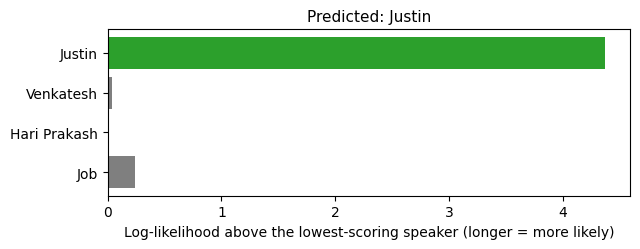

In [15]:
# 10b. Record from the microphone and identify the speaker (re-run for each recording)
import subprocess
from base64 import b64decode
from IPython.display import Javascript
from google.colab import output

RECORD_SECONDS = 6

display(Javascript('''
const sleep = t => new Promise(r => setTimeout(r, t));
const b2text = blob => new Promise(res => { const r = new FileReader(); r.onloadend = e => res(e.srcElement.result); r.readAsDataURL(blob); });
var record = time => new Promise(async resolve => {
  const note = document.createElement('p'); note.style.fontSize = '18px'; document.body.appendChild(note);
  try {
    note.innerText = 'Waiting for microphone permission... (click Allow near the address bar)';
    const stream = await navigator.mediaDevices.getUserMedia({audio: true});
    const rec = new MediaRecorder(stream); const chunks = [];
    rec.ondataavailable = e => chunks.push(e.data);
    rec.onstop = async () => { stream.getTracks().forEach(t => t.stop()); note.innerText = 'Recording finished.'; resolve(await b2text(new Blob(chunks))); };
    rec.start(); note.innerText = '🔴 RECORDING - speak now!';
    await sleep(time); rec.stop();
  } catch (err) {
    note.style.color = 'red'; note.innerText = 'Microphone error: ' + err.name + ' - allow mic access for this site and re-run.';
    resolve('ERROR:' + err.name);
  }
});'''))
data = output.eval_js(f'record({RECORD_SECONDS * 1000})')
if data.startswith('ERROR'):
    print('Microphone not available:', data, '- allow microphone access and re-run this cell.')
else:
    open('/tmp/mic_in', 'wb').write(b64decode(data.split(',')[1]))
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', '/tmp/mic_in', '-ac', '1', '-ar', str(SR), '/tmp/mic.wav'], check=True)
    identify(load_wav('/tmp/mic.wav'))

Speech detected: 2.8 s   ->   PREDICTED SPEAKER: Justin (spk01)   (true: Justin (spk01), CORRECT)


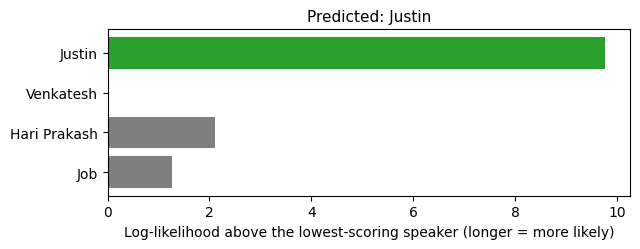

Speech detected: 2.8 s   ->   PREDICTED SPEAKER: Venkatesh (spk02)   (true: Venkatesh (spk02), CORRECT)


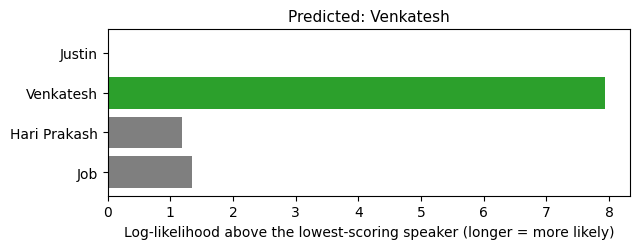

Speech detected: 3.0 s   ->   PREDICTED SPEAKER: Hari Prakash (spk03)   (true: Hari Prakash (spk03), CORRECT)


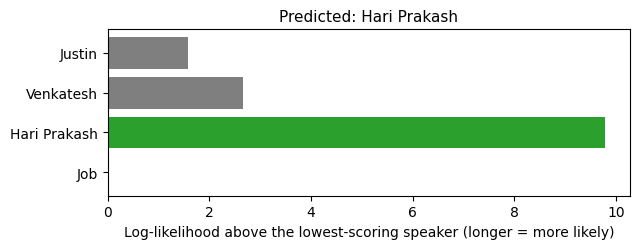

Speech detected: 2.9 s   ->   PREDICTED SPEAKER: Job (spk04)   (true: Job (spk04), CORRECT)


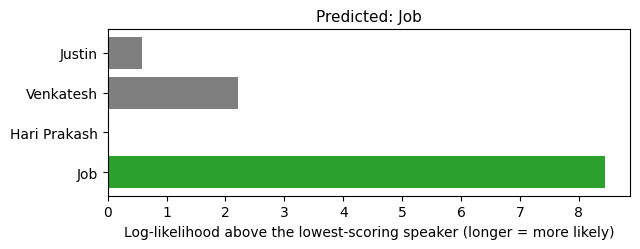

In [14]:
# 10c. Backup demo: one held-out clip per speaker (never used in training)
for spk in labels:
    print('=' * 70)
    identify(demo_clips[spk][np.random.randint(len(demo_clips[spk]))], true_speaker=spk)